# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** Sahithi Dadala

**Roll Number:**AP24110010738

**Date:** 09-10-2026

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [ ]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


**Predict, then think:** which has higher entropy, a 70/30 split or a 90/10 split? Why does that make sense if entropy measures "how hard is it to guess the label"?

*Your answer:*I predict that a 70/30 split has higher entropy than a 90/10 split because the labels are more balanced, making them harder to guess.


### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [ ]:
# Write your answer here
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p)))

parent = entropy([8, 6])
left = entropy([6, 0])
right = entropy([2, 6])

weighted_child = (6/14) * left + (8/14) * right
information_gain = parent - weighted_child

print('Parent entropy:', parent)
print('Left child entropy:', left)
print('Right child entropy:', right)
print('Information gain:', information_gain)

Parent entropy: 0.9852281360342515
Left child entropy: -0.0
Right child entropy: 0.8112781244591328
Information gain: 0.5216406363433185


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [ ]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [ ]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [ ]:
# Write your answer her
import numpy as np
import pandas as pd

def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p)))

def info_gain(df, attribute, target='Play'):
    parent_entropy = entropy(df[target].value_counts())
    weighted_entropy = 0

    for value, group in df.groupby(attribute):
        weighted_entropy += (len(group) / len(df)) * entropy(
            group[target].value_counts()
        )

    return parent_entropy - weighted_entropy

# Information gain for each attribute
for attr in ['Outlook', 'Temperature', 'Humidity']:
    print(f'{attr}: {info_gain(tennis, attr):.4f}')

# Find root attribute
root = max(
    ['Outlook', 'Temperature', 'Humidity'],
    key=lambda attr: info_gain(tennis, attr)
)
print('Root attribute:', root)

# Filter the Sunny branch
branch = tennis[tennis['Outlook'] == 'Sunny']

# Compute information gain for the remaining attributes
for attr in ['Temperature', 'Humidity', 'Wind']:
    print(f'{attr} (Sunny branch): {info_gain(branch, attr):.4f}')


Outlook: 0.2467
Temperature: 0.0292
Humidity: 0.1518
Root attribute: Outlook
Temperature (Sunny branch): 0.5710
Humidity (Sunny branch): 0.9710
Wind (Sunny branch): 0.0200


**Reflection:** `Overcast` became a leaf immediately. In your own words, why does a pure branch need no further splitting?

*Your answer:*

A pure branch needs no further splitting because all samples have the same label, so the prediction is already clear and entropy is zero.



## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


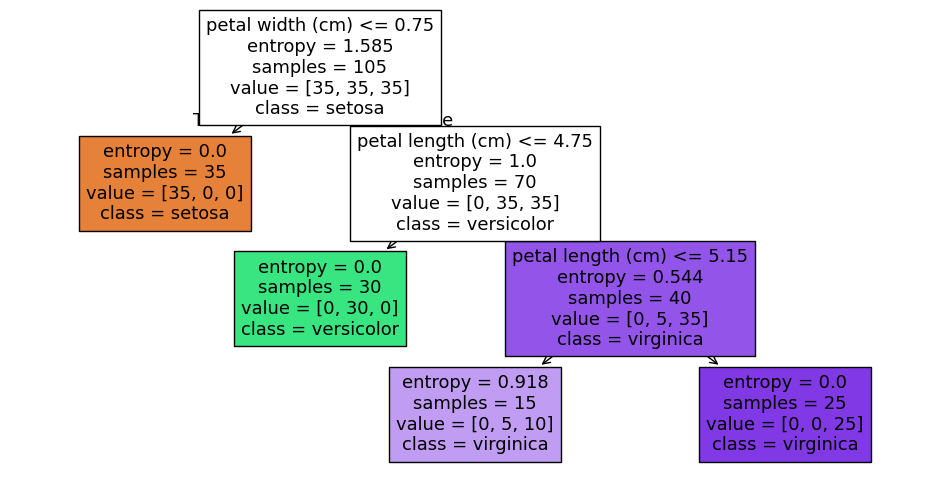

In [ ]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


Depth 1: Train Accuracy = 0.6667, Test Accuracy = 0.6667
Depth 2: Train Accuracy = 0.9524, Test Accuracy = 0.9556
Depth 3: Train Accuracy = 0.9524, Test Accuracy = 0.9556
Depth 4: Train Accuracy = 0.9524, Test Accuracy = 0.9333
Depth 5: Train Accuracy = 0.9714, Test Accuracy = 0.9778
Depth 6: Train Accuracy = 0.9810, Test Accuracy = 0.9778
Depth 7: Train Accuracy = 0.9810, Test Accuracy = 0.9778
Depth 8: Train Accuracy = 0.9905, Test Accuracy = 0.9778
Depth 9: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 10: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 11: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 12: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 13: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 14: Train Accuracy = 1.0000, Test Accuracy = 0.9778
Depth 15: Train Accuracy = 1.0000, Test Accuracy = 0.9778


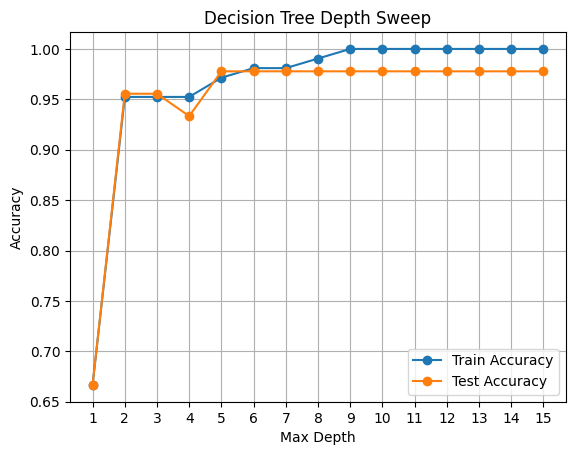

Best depth: 5
Best test accuracy: 0.9777777777777777


In [ ]:
# Write your answer here

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

iris = load_iris(as_frame=True)
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1, stratify=y
)

depths = range(1, 16)
train_acc = []
test_acc = []

for depth in depths:
    tree = DecisionTreeClassifier(
        criterion='entropy', max_depth=depth, random_state=1
    )
    tree.fit(X_train, y_train)

    train_acc.append(accuracy_score(y_train, tree.predict(X_train)))
    test_acc.append(accuracy_score(y_test, tree.predict(X_test)))

    print(f'Depth {depth}: Train Accuracy = {train_acc[-1]:.4f}, '
          f'Test Accuracy = {test_acc[-1]:.4f}')

# Plot accuracies
plt.plot(depths, train_acc, marker='o', label='Train Accuracy')
plt.plot(depths, test_acc, marker='o', label='Test Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree Depth Sweep')
plt.xticks(list(depths))
plt.legend()
plt.grid(True)
plt.show()

# Best test accuracy
best_index = test_acc.index(max(test_acc))
print('Best depth:', list(depths)[best_index])
print('Best test accuracy:', test_acc[best_index])


**Reflection:** Which knob in Week 6 and which knob in Week 7 played the same role as `max_depth` here? What happens at each extreme?

*Your answer:*


# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [ ]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


Decision Tree test accuracy: 0.8814814814814815
Max depth 3: Test accuracy = 0.5296
Max depth 6: Test accuracy = 0.8537
Max depth 10: Test accuracy = 0.8796


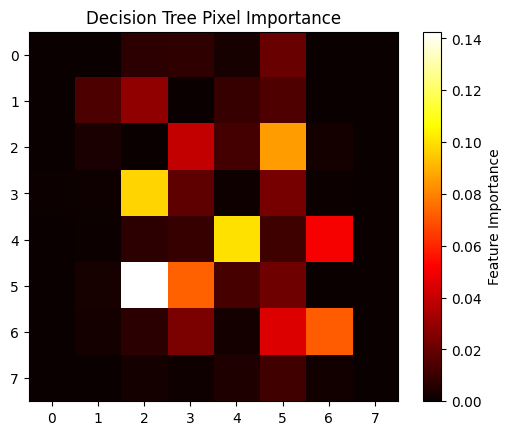

In [ ]:
# Write your answer here
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

# Decision Tree without scaling
tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(Xd_train, yd_train)

print('Decision Tree test accuracy:', accuracy_score(yd_test, tree.predict(Xd_test)))

# Try different max_depth values
for depth in [3, 6, 10]:
    tree = DecisionTreeClassifier(
        criterion='entropy', max_depth=depth, random_state=1
    )
    tree.fit(Xd_train, yd_train)
    print(f'Max depth {depth}: Test accuracy = {accuracy_score(yd_test, tree.predict(Xd_test)):.4f}')

# Pixel importance visualization
tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(Xd_train, yd_train)

importance = tree.feature_importances_.reshape(8, 8)

plt.imshow(importance, cmap='hot')
plt.colorbar(label='Feature Importance')
plt.title('Decision Tree Pixel Importance')
plt.show()

**Reflection:** Is the tree more or less accurate than KNN on digits? Offer one reason, using what the importance map shows you.

*Your answer:*


# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [ ]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [ ]:
# Write your answer here
from sklearn.tree import DecisionTreeClassifier, export_text

tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(X_text, labels)

print(export_text(tree, feature_names=list(vocab)))

sentences = [
    'the striker scored a goal',
    'your ambiguous sentence from Week 7'
]

X_new = vectorizer.transform(sentences)
predictions = tree.predict(X_new)

for sentence, prediction in zip(sentences, predictions):
    print(sentence, '->', prediction)




|--- is <= 0.50
|   |--- the <= 1.50
|   |   |--- goal <= 0.50
|   |   |   |--- class: politics
|   |   |--- goal >  0.50
|   |   |   |--- class: sports
|   |--- the >  1.50
|   |   |--- class: sports
|--- is >  0.50
|   |--- class: technology

the striker scored a goal -> sports
your ambiguous sentence from Week 7 -> politics


**Reflection:** If you added 3 more sentences per topic, would you expect the same split words? What does that tell you about trusting a tree trained on very little data?

*Your answer:*I would not expect the same split words because adding more sentences can change the decision tree. This shows that trees trained on very little data may not be reliable and can overfit.


## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
